# Versió B — Sense suavitzat + FPCA / MFPCA + Random Forest: eòlica i preu (ESIOS)

Autor: Leonel Fernando Nabaza Ruibal

$$
\underbrace{\text{dades discretes}}_{\text{ESIOS}}
\;\longrightarrow\;
\underbrace{x_i(t_1),\dots,x_i(t_T)}_{\text{valors a la malla}}
\;\longrightarrow\;
\underbrace{\boldsymbol{\xi}_i}_{\text{FPCA / MFPCA}}
\;\longrightarrow\;
\underbrace{\hat{\boldsymbol{\xi}}_{n+1}}_{\text{Random Forest}}
\;\longrightarrow\;
\underbrace{\hat{x}_{n+1}(t)}_{\text{reconstrucció}}
$$

**Versió B (aquest notebook):** **no** es fa cap suavitzat: cada dia és el vector de valors
observats a la malla (com al notebook anterior) i les integrals es calculen amb la regla del trapezi.
La versió A fa exactament el mateix però suavitzant abans amb B-splines.

**Canvis respecte al notebook anterior:**

1. Representació funcional explícita (versió A: suavitzat; versió B: sense suavitzat).
2. Secció dedicada a **quina variància** es calcula (discreta o funcional) i com ho comprovem.
3. Més gràfics de cada pas, inclosa la comparació *observacions vs suavitzat vs aproximació FPCA / MFPCA*.
4. **Mateix nombre de components** $K$ per a FPCA i MFPCA: el màxim dels necessaris per explicar el 95 %.
5. Errors de predicció en **versió funcional** (integrals), no puntual.
6. Només dades des de l'**1-10-2025**, quan el preu del mercat diari passa a resolució de 15 min.
7. Predicció dels scores amb **Random Forest** (el VAR es manté només com a referència).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.interpolate import BSpline
from scipy.linalg import eigh
from sklearn.ensemble import RandomForestRegressor
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore")
trapz = getattr(np, "trapezoid", None) or np.trapz   # np.trapz s'ha reanomenat a NumPy 2

VERSIO = "B"
SUAVITZAT = False         # True: versió A (B-splines) | False: versió B (valors a la malla)

CARPETA = "dades_esios"
ZONA = "Europe/Madrid"
DATA_INICI = "2025-10-01"   # primer dia del mercat diari a 15 min
DATA_FI = "2026-11-01"      # exclosa

N_BASE = {"eòlica": 48, "preu": 48}   # nombre de B-splines (només versió A)
LAMBDES = np.logspace(-4, 3, 30)       # penalitzacions que es proven amb GCV (només versió A)

VAR_EXPLICADA = 0.95   # criteri per triar el nombre de components
K_UNIV_MFPCA = 10      # components univariants de cada variable dins la MFPCA
N_TEST = 60            # dies de l'avaluació rodant
LAGS = [1, 2, 7]       # retards dels scores que fa servir el Random Forest
RF_PARAMS = dict(n_estimators=300, min_samples_leaf=3, max_features=1 / 3,
                 random_state=0, n_jobs=-1)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

---
# Part 1 — Dades discretes

Es descarreguen (o es llegeixen de la memòria cau) l'eòlica en temps real (5 min, 288 punts/dia)
i el preu del mercat diari (15 min, 96 punts/dia). Només es fan servir dades a partir de
l'**1-10-2025**: abans el preu era horari i barrejar les dues resolucions obligaria a
inventar valors o a perdre resolució.

Els dies han de ser **consecutius** (el model de predicció fa servir el dia anterior). Els dies
de canvi d'hora es tracten com al notebook anterior: l'hora repetida es promitja i l'hora
inexistent s'interpola linealment.

In [2]:
from esios_corbes_diaries import crear_dataset

_ = crear_dataset(DATA_INICI, DATA_FI, carpeta=CARPETA)

Període: 2025-10-01 -> 2026-11-01 (exclòs)
Eòlica:
  indicador 551: «Generación T.Real eólica»
  2025-10-01 -> 2025-10-21  (6048 valors)
  2025-10-22 -> 2025-11-11  (6060 valors)
  2025-11-12 -> 2025-12-02  (6048 valors)
  2025-12-03 -> 2025-12-23  (6048 valors)
  2025-12-24 -> 2026-01-13  (6048 valors)
  2026-01-14 -> 2026-02-03  (6048 valors)
  2026-02-04 -> 2026-02-24  (6048 valors)
  2026-02-25 -> 2026-03-17  (6048 valors)
  2026-03-18 -> 2026-04-07  (6036 valors)


  2026-04-08 -> 2026-04-28  (6048 valors)
  2026-04-29 -> 2026-05-19  (6048 valors)
  2026-05-20 -> 2026-06-09  (6048 valors)
  2026-06-10 -> 2026-06-30  (6048 valors)
  2026-07-01 -> 2026-07-21  (6048 valors)
  2026-07-22 -> 2026-08-11  (6048 valors)
  2026-08-12 -> 2026-09-01  (6048 valors)
  2026-09-02 -> 2026-09-22  (6048 valors)
  2026-09-23 -> 2026-10-13  (6048 valors)
  2026-10-14 -> 2026-10-31  (5196 valors)
  zona seleccionada: Península  (disponibles: ['Península'])


  resolució observada: 5 min (esperada 5 min)
  dies totals: 396  |  complets: 393  |  descartats: 3
Preu:
  indicador 600: «Precio mercado SPOT Diario»
  2025-10-01 -> 2025-10-21  (12096 valors)
  2025-10-22 -> 2025-11-11  (12120 valors)
  2025-11-12 -> 2025-12-02  (12096 valors)
  2025-12-03 -> 2025-12-23  (12096 valors)
  2025-12-24 -> 2026-01-13  (12096 valors)
  2026-01-14 -> 2026-02-03  (12096 valors)
  2026-02-04 -> 2026-02-24  (12096 valors)
  2026-02-25 -> 2026-03-17  (12096 valors)


  2026-03-18 -> 2026-04-07  (12072 valors)
  2026-04-08 -> 2026-04-28  (12096 valors)
  2026-04-29 -> 2026-05-19  (12096 valors)
  2026-05-20 -> 2026-06-09  (12096 valors)
  2026-06-10 -> 2026-06-30  (12096 valors)
  2026-07-01 -> 2026-07-21  (12096 valors)
  2026-07-22 -> 2026-08-11  (12096 valors)
  2026-08-12 -> 2026-09-01  (12096 valors)
  2026-09-02 -> 2026-09-22  (12096 valors)
  2026-09-23 -> 2026-10-13  (12096 valors)


  2026-10-14 -> 2026-10-31  (10392 valors)
  zona seleccionada: España  (disponibles: ['Portugal', 'Francia', 'España', 'Alemania', 'Bélgica', 'Países Bajos'])


  resolució observada: 15 min (esperada 15 min)
  dies totals: 396  |  complets: 393  |  descartats: 3

Dies comuns: 393
Fitxers guardats a 'dades_esios/'


In [3]:
def corbes_consecutives(fitxer, divisor=1.0):
    # Sèrie original -> (matriu dies x punts del dia amb dies consecutius, malla en hores)
    df = pd.read_csv(fitxer)
    t = pd.to_datetime(df["datetime_utc"], utc=True).dt.tz_convert(ZONA)
    resolucio = int(t.drop_duplicates().sort_values().diff().median().total_seconds() // 60)
    df = df.assign(dia=t.dt.date,
                   minut=t.dt.hour * 60 + t.dt.minute,
                   value=pd.to_numeric(df["value"], errors="coerce") / divisor)
    m = df.pivot_table(index="dia", columns="minut", values="value", aggfunc="mean")
    m = m.reindex(columns=np.arange(0, 24 * 60, resolucio))
    m.index = pd.to_datetime(m.index)
    m = m.reindex(pd.date_range(m.index.min(), m.index.max()))   # cap dia perdut
    buits = m.index[m.isna().any(axis=1)]
    print(f"{fitxer}: resolució {resolucio} min ({m.shape[1]} punts/dia), {len(m)} dies, "
          f"punts buits {int(m.isna().sum().sum())} als dies {[d.date().isoformat() for d in buits]}")
    return m.interpolate(axis=1, limit_direction="both"), m.columns.to_numpy() / 60


E, te = corbes_consecutives(f"{CARPETA}/eolica_raw.csv", divisor=1000)   # GW
P, tp = corbes_consecutives(f"{CARPETA}/preu_raw.csv")                   # €/MWh

dies = E.index.intersection(P.index)
Xe, Xp = E.loc[dies].to_numpy(), P.loc[dies].to_numpy()
n = len(dies)
n_train = n - N_TEST
VARS = {"eòlica": dict(X=Xe, t=te, unitat="GW"), "preu": dict(X=Xp, t=tp, unitat="€/MWh")}
print(f"\nDies consecutius: {n} ({dies.min().date()} -> {dies.max().date()})")
print(f"Entrenament inicial: {n_train} dies  |  prova: {N_TEST} dies (des de {dies[n_train].date()})")
print(f"Eòlica: {Xe.shape}   Preu: {Xp.shape}")

dades_esios/eolica_raw.csv: resolució 5 min (288 punts/dia), 396 dies, punts buits 12 als dies ['2026-03-29']
dades_esios/preu_raw.csv: resolució 15 min (96 punts/dia), 396 dies, punts buits 4 als dies ['2026-03-29']

Dies consecutius: 396 (2025-10-01 -> 2026-10-31)
Entrenament inicial: 336 dies  |  prova: 60 dies (des de 2026-09-02)
Eòlica: (396, 288)   Preu: (396, 96)


### Gràfics de les dades discretes

1. Tres dies d'exemple: cada punt és una observació (cada 5 min a l'eòlica, cada 15 min al preu).
2. Mapa de calor de tots els dies: cada fila és un dia i el color és el valor.
3. Mitjana diària al llarg del període: mostra la tendència i el canvi de nivell del preu.

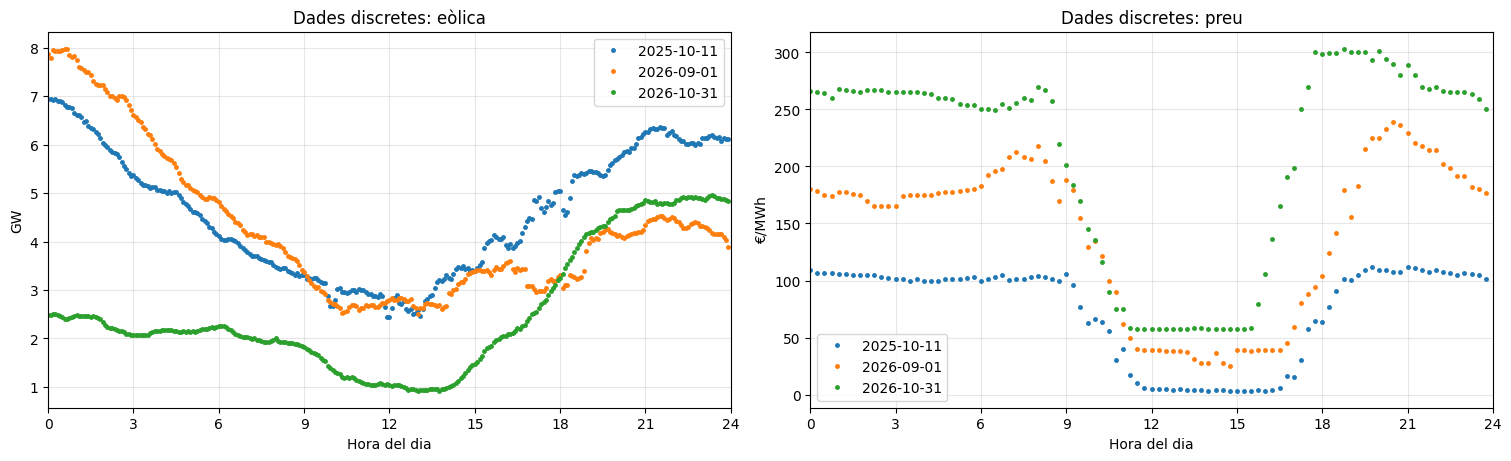

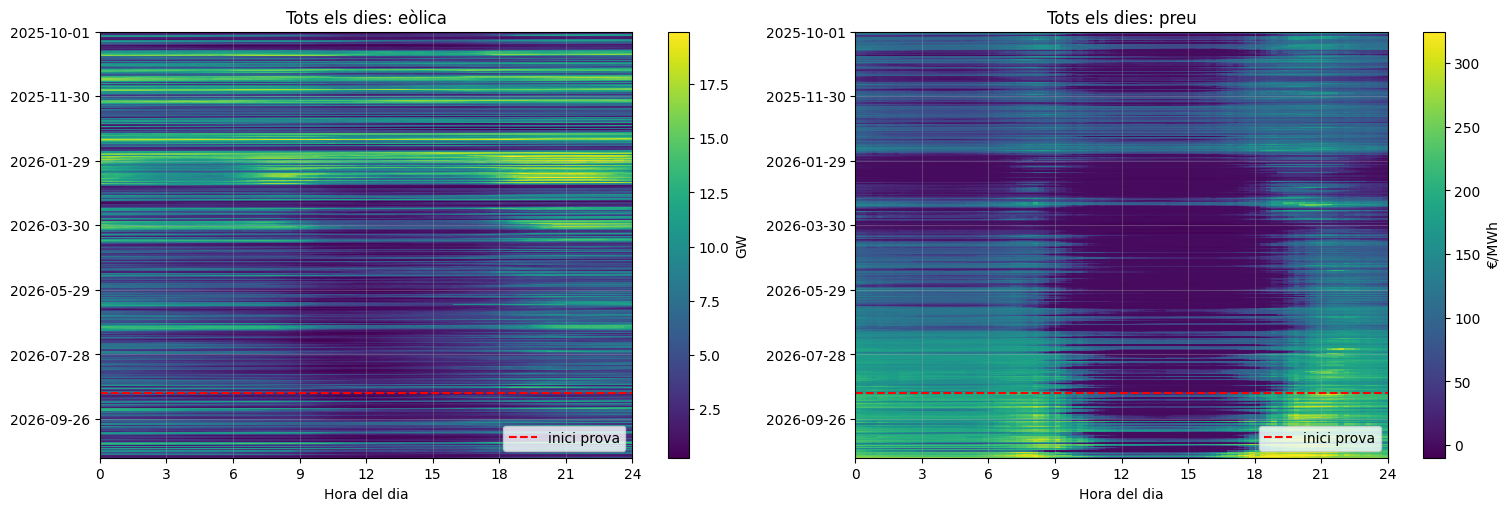

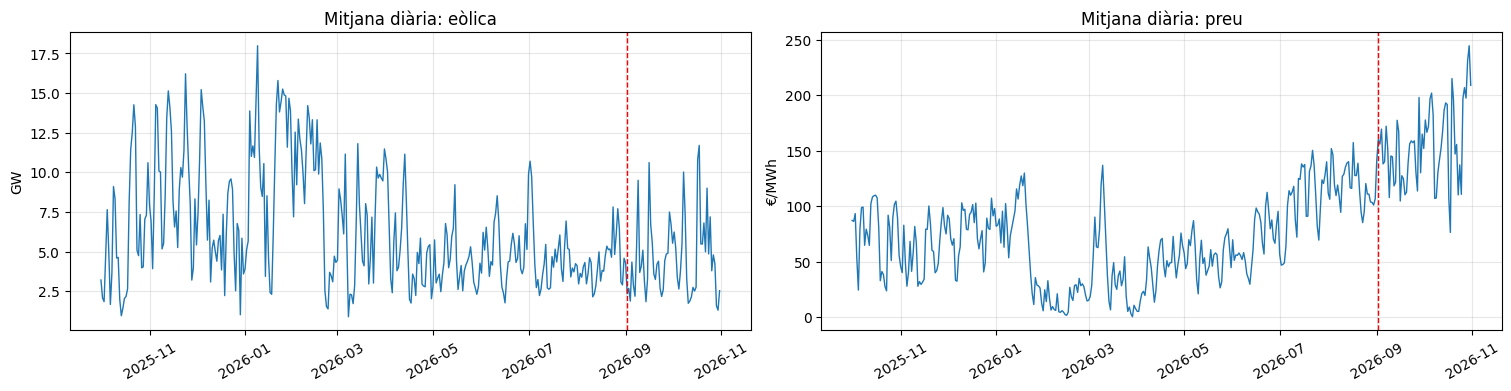

In [4]:
exemples = [dies[10], dies[n_train - 1], dies[-1]]
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5), constrained_layout=True)
for ax, (nom, v) in zip(axs, VARS.items()):
    for dia in exemples:
        i = dies.get_loc(dia)
        ax.plot(v["t"], v["X"][i], "o", ms=2.5, label=str(dia.date()))
    ax.set_title(f"Dades discretes: {nom}"); ax.set_ylabel(v["unitat"])
    ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 3)); ax.set_xlabel("Hora del dia"); ax.legend()
plt.show()

fig, axs = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
for ax, (nom, v) in zip(axs, VARS.items()):
    im = ax.imshow(v["X"], aspect="auto", cmap="viridis",
                   extent=[0, 24, n, 0], interpolation="nearest")
    ax.axhline(n_train, color="red", lw=1.5, ls="--", label="inici prova")
    pos = np.arange(0, n, 60)
    ax.set_yticks(pos); ax.set_yticklabels([str(dies[p].date()) for p in pos])
    ax.set_xticks(range(0, 25, 3)); ax.set_xlabel("Hora del dia")
    ax.set_title(f"Tots els dies: {nom}"); ax.legend(loc="lower right")
    fig.colorbar(im, ax=ax, label=v["unitat"])
plt.show()

fig, axs = plt.subplots(1, 2, figsize=(15, 3.8), constrained_layout=True)
for ax, (nom, v) in zip(axs, VARS.items()):
    ax.plot(dies, v["X"].mean(1), lw=1)
    ax.axvline(dies[n_train], color="red", ls="--", lw=1)
    ax.set_title(f"Mitjana diària: {nom}"); ax.set_ylabel(v["unitat"]); ax.tick_params(axis="x", rotation=30)
plt.show()

---
# Part 2 — Dataset funcional sense suavitzat

En aquesta versió **no** es fa cap suavitzat: la funció del dia $i$ és el vector de valors observats a
la malla, i entre dos punts consecutius s'entén que la funció és lineal (és el que suposa la regla
del trapezi). Formalment, és com fer servir una base de funcions "barret" (lineals a trossos) centrades
a cada punt de la malla, amb coeficients iguals als valors observats:

$$
x^{(j)}_i(t) \approx \sum_{l=1}^{T} x^{(j)}_i(t_l)\, h_l(t)
$$

Les integrals es calculen amb la **regla del trapezi**. Amb la mateixa notació que la versió A,
els "coeficients" són $C = X$ i la matriu que fa d'integral és diagonal amb els pesos del trapezi:

$$
\int x_i(t)\,x_{i'}(t)\,dt \approx \mathbf{x}_i^\top W \mathbf{x}_{i'},
\qquad
W = \operatorname{diag}(w_1,\dots,w_T),\quad
w_l = \begin{cases}\Delta/2 & l = 1, T\\ \Delta & \text{altrament}\end{cases}
$$

amb $\Delta$ la separació entre punts (5 min a l'eòlica, 15 min al preu). Així el codi de FPCA i MFPCA
és **idèntic** al de la versió A: només canvien $C$ i $W$.

In [5]:
def base_bsplines(a, b, q, grau=3):
    # Vector de nusos d'una base de q B-splines de grau 'grau' amb nusos equiespaiats a [a, b]
    nusos = np.linspace(a, b, q - grau + 1)
    return np.r_[[a] * grau, nusos, [b] * grau], nusos


def avalua_base(nusos_ext, x, grau=3):
    # Matriu len(x) x q amb les B-splines avaluades als punts x
    x = np.clip(x, nusos_ext[0], nusos_ext[-1])
    return BSpline.design_matrix(x, nusos_ext, grau).toarray()


def gram_bsplines(nusos_ext, nusos, grau=3):
    # W_kl = integral de b_k(t) b_l(t), exacta amb Gauss-Legendre a cada interval
    xg, wg = np.polynomial.legendre.leggauss(grau + 1)
    W = 0
    for a, b in zip(nusos[:-1], nusos[1:]):
        x = (b - a) / 2 * xg + (a + b) / 2
        Bx = avalua_base(nusos_ext, x, grau)
        W = W + Bx.T @ (Bx * ((b - a) / 2 * wg)[:, None])
    return W


def pesos_trapezi(t):
    w = np.full(len(t), t[1] - t[0])
    w[[0, -1]] /= 2
    return w


def representacio(X, t, q):
    # Retorna el dataset funcional d'una variable: coeficients C, matriu W i matrius d'avaluació
    tf = np.linspace(t[0], t[-1], 600)   # malla fina per dibuixar
    if not SUAVITZAT:
        return dict(C=X.copy(), W=np.diag(pesos_trapezi(t)), B=np.eye(len(t)),
                    tf=t, Bf=np.eye(len(t)), q=len(t))
    nusos_ext, nusos = base_bsplines(t[0], t[-1], q)
    B = avalua_base(nusos_ext, t)
    D2 = np.diff(np.eye(q), 2, axis=0)
    Pen = D2.T @ D2
    T = len(t)
    gcv = []
    for lam in LAMBDES:
        H = B @ np.linalg.solve(B.T @ B + lam * Pen, B.T)
        rss = np.sum((X - X @ H.T) ** 2) / len(X)
        gcv.append(T * rss / (T - np.trace(H)) ** 2)
    lam = LAMBDES[int(np.argmin(gcv))]
    A = np.linalg.solve(B.T @ B + lam * Pen, B.T)       # q x T
    return dict(C=X @ A.T, W=gram_bsplines(nusos_ext, nusos), B=B, tf=tf,
                Bf=avalua_base(nusos_ext, tf), q=q, lam=lam, gcv=np.array(gcv),
                df=np.trace(B @ A), nusos_ext=nusos_ext)


for nom, v in VARS.items():
    v["R"] = representacio(v["X"], v["t"], N_BASE[nom])
    R = v["R"]
    res = v["X"] - R["C"] @ R["B"].T      # residus a la malla
    if SUAVITZAT:
        print(f"{nom}: q = {R['q']} B-splines, lambda (GCV) = {R['lam']:.2e}, "
              f"graus de llibertat efectius = {R['df']:.1f}, "
              f"RMSE del suavitzat = {np.sqrt(np.mean(res ** 2)):.3f} {v['unitat']}")
    else:
        print(f"{nom}: {R['q']} valors per dia, W = diag(pesos del trapezi), "
              f"suma dels pesos = {np.diag(R['W']).sum():.4f} h (= longitud del domini)")

eòlica: 288 valors per dia, W = diag(pesos del trapezi), suma dels pesos = 23.9167 h (= longitud del domini)
preu: 96 valors per dia, W = diag(pesos del trapezi), suma dels pesos = 23.7500 h (= longitud del domini)


### Gràfic: observacions i funció implícita

Sense suavitzat, la funció de cada dia és la interpolació lineal dels punts observats
(és el que integra la regla del trapezi).

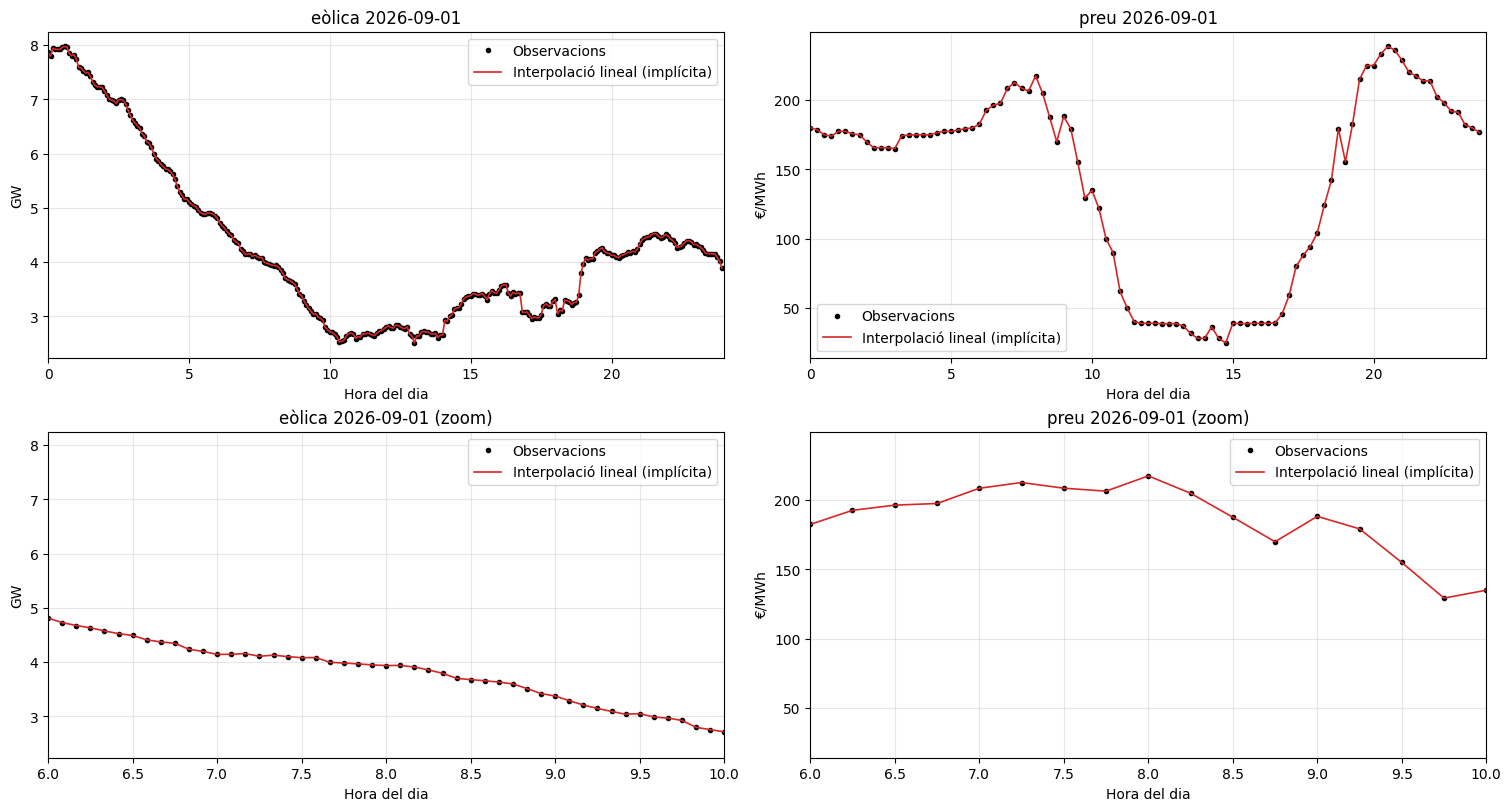

In [6]:
i = n_train - 1
fig, axs = plt.subplots(2, 2, figsize=(15, 8), constrained_layout=True)
for col, (nom, v) in enumerate(VARS.items()):
    for fila, (x0, x1) in enumerate([(0, 24), (6, 10)]):
        ax = axs[fila, col]
        ax.plot(v["t"], v["X"][i], "o", ms=3, color="black", label="Observacions")
        ax.plot(v["t"], v["X"][i], color="tab:red", lw=1.2, label="Interpolació lineal (implícita)")
        ax.set_xlim(x0, x1); ax.set_ylabel(v["unitat"]); ax.set_xlabel("Hora del dia")
        ax.set_title(f"{nom} {dies[i].date()}" + ("" if fila == 0 else " (zoom)")); ax.legend()
plt.show()

---
# Part 3 — Quina variància calculem?

"Mostral" i "funcional" no són oposats: **totes** les variàncies del notebook són **mostrals**
(estimades amb els $n$ dies, dividint per $n-1$). La pregunta és si són **discretes** (sumes sobre
els punts de la malla) o **funcionals** (integrals sobre el dia).

| Quantitat | Fórmula | Tipus |
|---|---|---|
| Variància puntual | $s^2(t_l) = \frac{1}{n-1}\sum_i \big(x_i(t_l)-\bar x(t_l)\big)^2$ | discreta, un valor per instant |
| Variància total **discreta** | $\sum_{l=1}^T s^2(t_l)$ | discreta: depèn de quants punts té la malla |
| Variància total **funcional** | $\int_{\mathcal T} s^2(t)\,dt = \frac{1}{n-1}\sum_i \|x_i-\bar x\|^2_{L^2}$ | funcional: no depèn de la malla |
| Desviació total funcional | $s_j = \sqrt{\int s^2(t)\,dt}$ | la que fem servir per escalar |

La relació entre les dues totals és aproximadament $\int s^2 \approx \Delta \sum_l s^2(t_l)$:
si la malla és el doble de fina, la discreta es duplica i la funcional no canvia. Per això la
FPCA ha de fer servir la **funcional**.

**On fem servir la funcional:** a l'escalat de cada variable, als valors propis de la FPCA/MFPCA
(la seva suma és la variància total funcional) i al criteri del 95 %.

**Com la calculem:** amb la **regla del trapezi** sobre la variància puntual:

$$
\int_{\mathcal T} \widehat{\operatorname{Var}}\big(x(t)\big)\,dt \approx \sum_l w_l\, s^2(t_l)
= \operatorname{tr}\big(\widehat{V}\, W\big)
$$

**Com sabem que és aquesta i no la discreta:** a la Part 5 comprovem numèricament que la suma de
tots els valors propis de la FPCA coincideix amb la variància total funcional i **no** amb la discreta.

In [7]:
files = []
for nom, v in VARS.items():
    X, t, R = v["X"], v["t"], v["R"]
    s2 = X.var(axis=0, ddof=1)                         # variància puntual de les dades (discreta)
    Cc = R["C"] - R["C"].mean(0)
    V_C = Cc.T @ Cc / (n - 1)
    fila = {"variable": nom,
            "total discreta  Σ s²(t_l)": s2.sum(),
            "total funcional  ∫ s²(t) dt (trapezi, dades)": trapz(s2, t),
            "total funcional  tr(V W) (representació)": np.trace(V_C @ R["W"])}
    if SUAVITZAT:
        corbes_fines = R["C"] @ R["Bf"].T
        fila["total funcional  ∫ s²(t) dt (malla fina, suavitzat)"] = trapz(corbes_fines.var(0, ddof=1), R["tf"])
    fila["Δ (h)"] = t[1] - t[0]
    fila["Δ · total discreta"] = (t[1] - t[0]) * s2.sum()
    files.append(fila)
pd.DataFrame(files).set_index("variable").T.round(3)

variable,eòlica,preu
total discreta Σ s²(t_l),4387.752,322879.255
"total funcional ∫ s²(t) dt (trapezi, dades)",364.435,79759.265
total funcional tr(V W) (representació),364.435,79759.265
Δ (h),0.083,0.250
Δ · total discreta,365.646,80719.814


- **tr(V W)** és el que fa servir el codi de FPCA i coincideix amb la integral numèrica:
  és la variància **funcional**.
- La total discreta és molt més gran (per l'eòlica, uns 12 cops: 288 punts en 24 h) i només
  coincideix amb la funcional quan es multiplica per $\Delta$.

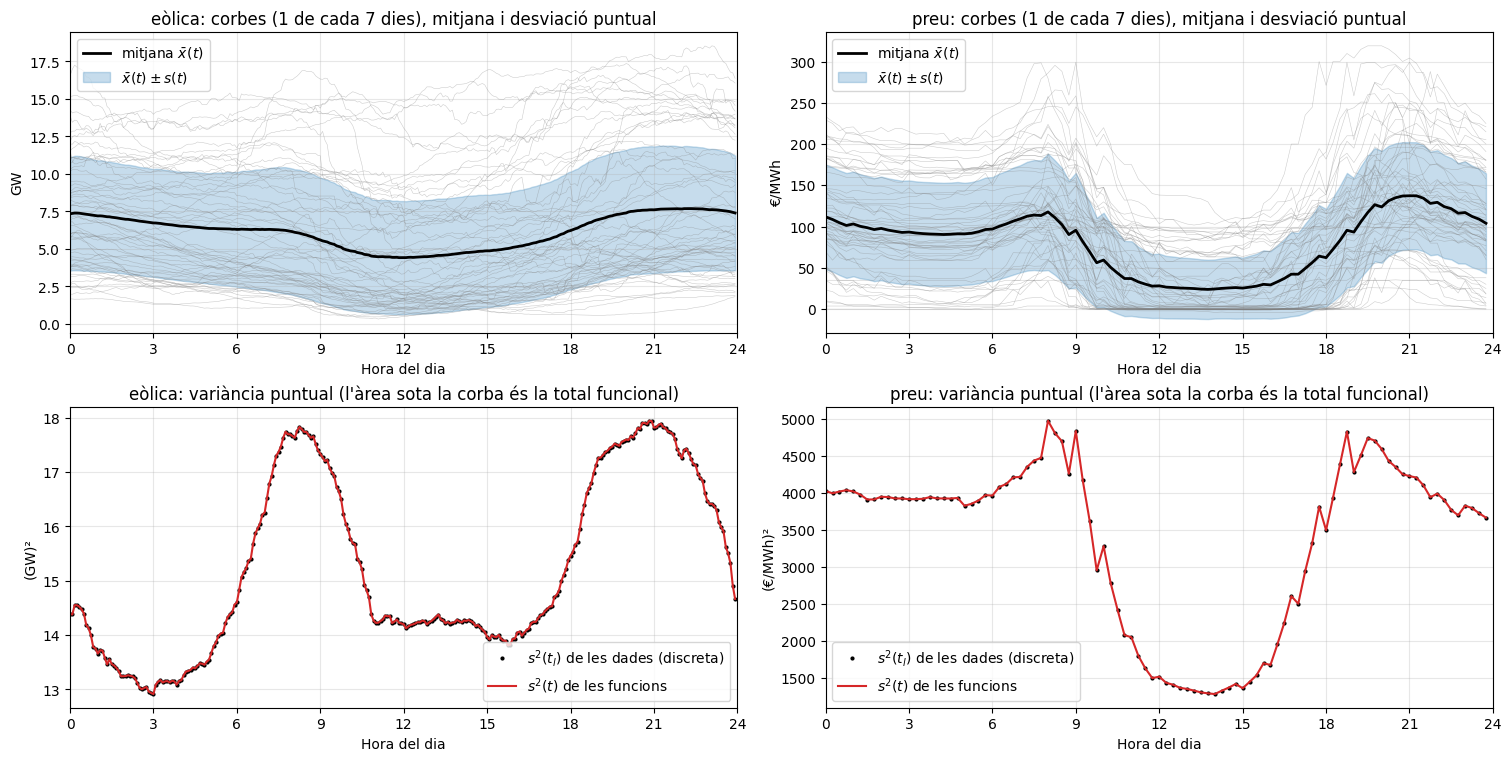

In [8]:
fig, axs = plt.subplots(2, 2, figsize=(15, 7.5), constrained_layout=True)
for col, (nom, v) in enumerate(VARS.items()):
    X, t, R = v["X"], v["t"], v["R"]
    Y = R["C"] @ R["Bf"].T                 # corbes funcionals avaluades a la malla de dibuix
    mu, sd = Y.mean(0), Y.std(0, ddof=1)
    ax = axs[0, col]
    ax.plot(R["tf"], Y[::7].T, color="grey", lw=0.4, alpha=0.4)
    ax.plot(R["tf"], mu, color="black", lw=2, label="mitjana $\\bar x(t)$")
    ax.fill_between(R["tf"], mu - sd, mu + sd, color="tab:blue", alpha=0.25, label="$\\bar x(t) \\pm s(t)$")
    ax.set_title(f"{nom}: corbes (1 de cada 7 dies), mitjana i desviació puntual")
    ax.set_ylabel(v["unitat"]); ax.legend()
    ax = axs[1, col]
    ax.plot(t, X.var(0, ddof=1), "o", ms=2, color="black", label="$s^2(t_l)$ de les dades (discreta)")
    ax.plot(R["tf"], Y.var(0, ddof=1), color="tab:red", lw=1.5, label="$s^2(t)$ de les funcions")
    ax.set_title(f"{nom}: variància puntual (l'àrea sota la corba és la total funcional)")
    ax.set_ylabel(f"({v['unitat']})²"); ax.legend()
for ax in axs.flat:
    ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 3)); ax.set_xlabel("Hora del dia")
plt.show()

---
# Part 4 — Centrat i escalat

Perquè cap variable no domini la MFPCA, cada variable es centra i es divideix per la seva
**desviació total funcional** $s_j$ (Part 3). Com que la representació és lineal, tot es fa sobre els
coeficients:

$$
\mathbf z^{(j)}_i = \frac{\mathbf c^{(j)}_i - \bar{\mathbf c}^{(j)}}{s_j},
\qquad s_j^2 = \operatorname{tr}\big(\widehat V_{C^{(j)}} W^{(j)}\big)
$$

Després de l'escalat, cada variable té variància total funcional 1. La mitjana i $s_j$ es calculen
**només amb els dies d'entrenament** (a l'avaluació rodant, amb els dies anteriors al dia predit).

In [9]:
def escala(C, W):
    # Mitjana dels coeficients i desviació total funcional
    mu = C.mean(0)
    Cc = C - mu
    s = np.sqrt(np.trace(Cc.T @ Cc @ W) / (len(C) - 1))
    return mu, s


def prepara(d):
    # Centra i escala cada variable amb els dies 0..d-1. Retorna llista de (mu, s, Z)
    out = []
    for v in VARS.values():
        mu, s = escala(v["R"]["C"][:d], v["R"]["W"])
        out.append((mu, s, (v["R"]["C"][:d] - mu) / s))
    return out


prep = prepara(n_train)
Ws = [v["R"]["W"] for v in VARS.values()]
for (mu, s, Z), (nom, v), W in zip(prep, VARS.items(), Ws):
    print(f"{nom}: s = {s:.3f} {v['unitat']}  ->  variància total funcional després d'escalar = "
          f"{np.trace(Z.T @ Z @ W) / (len(Z) - 1):.4f}")

eòlica: s = 19.537 GW  ->  variància total funcional després d'escalar = 1.0000
preu: s = 225.770 €/MWh  ->  variància total funcional després d'escalar = 1.0000


---
# Part 5 — Reducció de dimensió: FPCA vs MFPCA

### FPCA (per a cada variable)

Les funcions pròpies s'escriuen amb la mateixa representació que les dades,
$\phi_k(t) = \boldsymbol\phi_k^\top \mathbf b(t)$. L'equació $\int C(s,t)\phi(t)\,dt = \lambda\phi(s)$ es converteix en un problema matricial
(Ramsay & Silverman, cap. 8):

$$
W^{1/2}\,\widehat V_Z\,W^{1/2}\,\mathbf u_k = \lambda_k\,\mathbf u_k,
\qquad
\text{coeficients de } \phi_k = W^{-1/2}\mathbf u_k,
\qquad
\xi_{ik} = \int z_i(t)\phi_k(t)\,dt = \mathbf z_i^\top W\, \boldsymbol\phi_k
$$

La suma de **tots** els $\lambda_k$ és $\operatorname{tr}(\widehat V_Z W)$, la variància total funcional (= 1 després d'escalar).

### MFPCA (Happ & Greven, 2018, Proposició 5)

1. FPCA de cada variable amb $K_{\text{univ}} = 10$ components: scores $\xi^{(1)}_{ik}$, $\xi^{(2)}_{ik}$.
2. Matriu de covariàncies dels 20 scores concatenats, $\mathbf Z$ ($20 \times 20$).
3. Vectors propis $\mathbf c_m$ de $\mathbf Z$, amb valors propis $\nu_m$.
4. Funcions pròpies conjuntes: $\psi^{(j)}_m = \sum_k [\mathbf c_m]^{(j)}_k\,\phi^{(j)}_k$, i scores
   $\rho_{im} = \sum_j\sum_k [\mathbf c_m]^{(j)}_k\,\xi^{(j)}_{ik}$.

### Nombre de components

Es calcula quantes components calen per explicar el 95 % de la variància total funcional:
$K_1$ (FPCA eòlica), $K_2$ (FPCA preu) i $M$ (MFPCA, sobre la variància total de les dues variables,
que val 2). Per comparar en igualtat de condicions s'usa **el mateix nombre per a tot**:

$$
K = \max(K_1, K_2, M)
$$

La FPCA fa servir $K$ components per variable ($2K$ scores) i la MFPCA $K$ components conjuntes
($K$ scores). $K$ es tria amb els dies d'entrenament i es manté fix a l'avaluació.

In [10]:
def arrels(W):
    # W^(1/2) i W^(-1/2) d'una matriu simètrica definida positiva
    val, U = eigh(W)
    return (U * np.sqrt(val)) @ U.T, (U / np.sqrt(val)) @ U.T


def fpca(Z, W, K=None):
    # FPCA sobre coeficients Z (n x q) amb matriu d'integració W (q x q)
    W12, Wm12 = arrels(W)
    V = Z.T @ Z / (len(Z) - 1)
    lam, U = eigh(W12 @ V @ W12)
    ordre = np.argsort(lam)[::-1]
    lam, U = np.clip(lam[ordre], 0, None), U[:, ordre]
    K = len(lam) if K is None else K
    Phi = (Wm12 @ U)[:, :K]                       # coeficients de les funcions pròpies (columnes)
    return dict(lam=lam, Phi=Phi, S=Z @ W @ Phi, total=np.trace(V @ W))


def mfpca(Zs, Ws, K, K_univ=K_UNIV_MFPCA):
    # MFPCA de Happ & Greven a partir de FPCA univariants
    univ = [fpca(Z, W, K_univ) for Z, W in zip(Zs, Ws)]
    Xi = np.hstack([u["S"] for u in univ])            # scores univariants concatenats
    Zmat = Xi.T @ Xi / (len(Xi) - 1)
    nu, c = eigh(Zmat)
    ordre = np.argsort(nu)[::-1]
    nu, c = nu[ordre], c[:, ordre]
    talls = np.cumsum([0] + [K_univ] * len(Zs))
    Psi = [univ[j]["Phi"] @ c[talls[j]:talls[j + 1], :K] for j in range(len(Zs))]
    return dict(nu=nu, Psi=Psi, S=Xi @ c[:, :K], total=sum(u["total"] for u in univ))


def n_components(valors, total, p=VAR_EXPLICADA):
    return int(np.searchsorted(np.cumsum(valors) / total, p) + 1)


Zs = [Z for _, _, Z in prep]
f_e, f_p = fpca(Zs[0], Ws[0]), fpca(Zs[1], Ws[1])
m_all = mfpca(Zs, Ws, K=2 * K_UNIV_MFPCA)
K1 = n_components(f_e["lam"], f_e["total"])
K2 = n_components(f_p["lam"], f_p["total"])
M = n_components(m_all["nu"], m_all["total"])
K = max(K1, K2, M)
print(f"Components per al 95 %:  FPCA eòlica K1 = {K1},  FPCA preu K2 = {K2},  MFPCA M = {M}")
print(f"=> K = {K} per a tot: FPCA {K} + {K} = {2 * K} scores  |  MFPCA {K} scores\n")

print("Comprovació (Part 3): la suma de tots els valors propis és la variància total funcional")
for nom, f, (mu, s, Z), R in zip(VARS, [f_e, f_p], prep, [v["R"] for v in VARS.values()]):
    discreta = (Z @ R["B"].T).var(0, ddof=1).sum()    # variància total discreta a la malla
    print(f"  {nom}: Σ λ_k = {f['lam'].sum():.4f}   tr(V W) = {f['total']:.4f}   "
          f"total discreta = {discreta:.2f}")
print(f"  MFPCA: Σ ν_m = {m_all['nu'].sum():.4f} de {m_all['total']:.1f} "
      f"(la resta és la variància que no capturen les {K_UNIV_MFPCA} components univariants)")

Components per al 95 %:  FPCA eòlica K1 = 3,  FPCA preu K2 = 4,  MFPCA M = 6
=> K = 6 per a tot: FPCA 6 + 6 = 12 scores  |  MFPCA 6 scores

Comprovació (Part 3): la suma de tots els valors propis és la variància total funcional
  eòlica: Σ λ_k = 1.0000   tr(V W) = 1.0000   total discreta = 12.04
  preu: Σ λ_k = 1.0000   tr(V W) = 1.0000   total discreta = 4.05
  MFPCA: Σ ν_m = 1.9872 de 2.0 (la resta és la variància que no capturen les 10 components univariants)


**Comprovació amb FDApy.** A la versió B les dades són exactament les del notebook anterior, i la
nostra FPCA ha de donar els mateixos valors propis que `UFPCA(method="covariance")` de FDApy
(que diagonalitza $W^{1/2}\widehat V W^{1/2}$ amb pesos del trapezi). Si FDApy no està instal·lat,
la cel·la s'omet.

In [11]:
try:
    from FDApy.preprocessing.dim_reduction.ufpca import UFPCA
    from FDApy.representation.argvals import DenseArgvals
    from FDApy.representation.functional_data import DenseFunctionalData
    from FDApy.representation.values import DenseValues

    for nom, f, Z, v in zip(VARS, [f_e, f_p], Zs, VARS.values()):
        fd = DenseFunctionalData(DenseArgvals({"input_dim_0": v["t"]}), DenseValues(Z))
        u = UFPCA(n_components=K, method="covariance"); u.fit(fd)
        print(f"{nom}:  nostra FPCA {np.round(f['lam'][:K], 5)}")
        print(f"{' ' * len(nom)}   FDApy       {np.round(u.eigenvalues, 5)}")
except ImportError:
    print("FDApy no està instal·lat: s'omet la comprovació.")

eòlica:  nostra FPCA [0.84059 0.08401 0.04777 0.01122 0.00579 0.00335]
         FDApy       [0.84059 0.08401 0.04777 0.01122 0.00579 0.00335]
preu:  nostra FPCA [0.70088 0.19599 0.0421  0.01925 0.01296 0.00716]
       FDApy       [0.70088 0.19599 0.0421  0.01925 0.01296 0.00716]


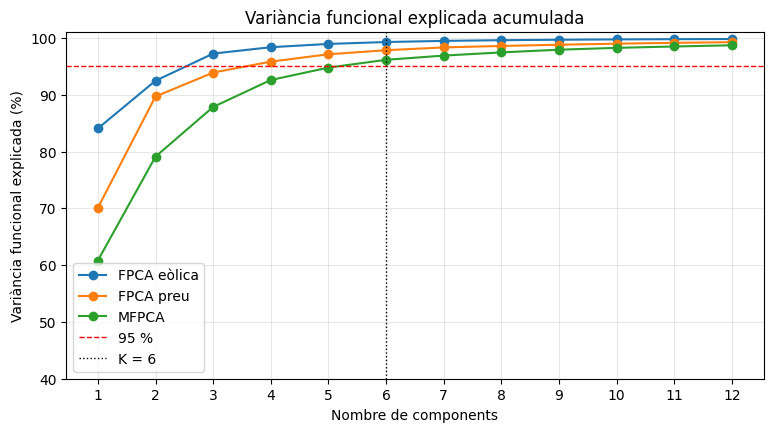

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for nom, valors, total in [("FPCA eòlica", f_e["lam"], f_e["total"]),
                           ("FPCA preu", f_p["lam"], f_p["total"]),
                           ("MFPCA", m_all["nu"], m_all["total"])]:
    acum = np.cumsum(valors[:12]) / total
    ax.plot(range(1, 13), 100 * acum, marker="o", label=nom)
ax.axhline(100 * VAR_EXPLICADA, color="red", ls="--", lw=1, label="95 %")
ax.axvline(K, color="black", ls=":", lw=1, label=f"K = {K}")
ax.set_xlabel("Nombre de components"); ax.set_ylabel("Variància funcional explicada (%)")
ax.set_xticks(range(1, 13)); ax.set_ylim(40, 101); ax.legend()
ax.set_title("Variància funcional explicada acumulada")
plt.show()

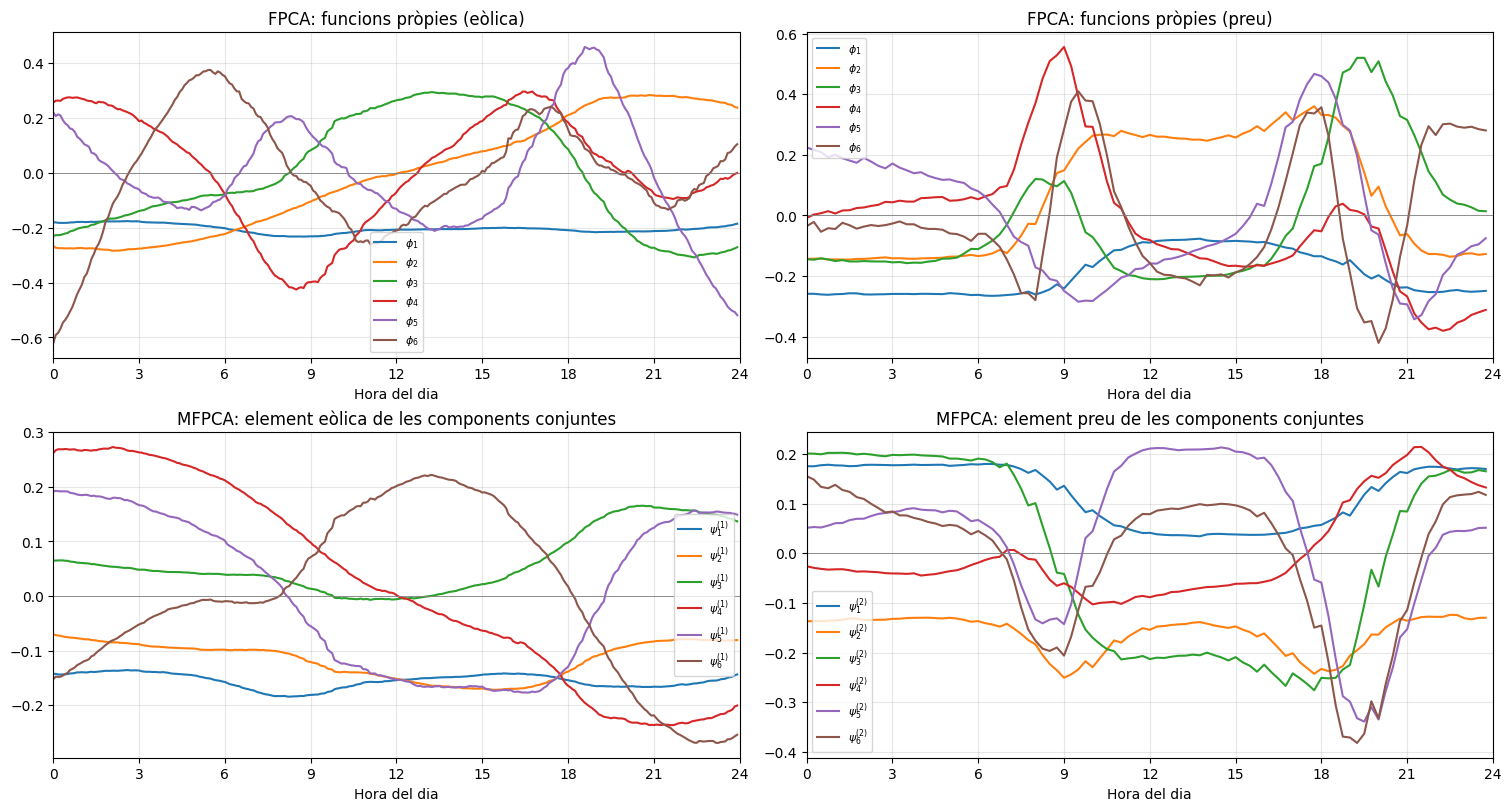

In [13]:
f_e, f_p = fpca(Zs[0], Ws[0], K), fpca(Zs[1], Ws[1], K)
mf = mfpca(Zs, Ws, K)
Rs = [v["R"] for v in VARS.values()]

fig, axs = plt.subplots(2, 2, figsize=(15, 8), constrained_layout=True)
for col, (f, R, nom) in enumerate(zip([f_e, f_p], Rs, VARS)):
    for k in range(K):
        axs[0, col].plot(R["tf"], R["Bf"] @ f["Phi"][:, k], label=f"$\\phi_{k + 1}$")
        axs[1, col].plot(R["tf"], R["Bf"] @ mf["Psi"][col][:, k], label=f"$\\psi^{{({col + 1})}}_{k + 1}$")
    axs[0, col].set_title(f"FPCA: funcions pròpies ({nom})")
    axs[1, col].set_title(f"MFPCA: element {nom} de les components conjuntes")
for ax in axs.flat:
    ax.axhline(0, color="grey", lw=0.6)
    ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 3)); ax.set_xlabel("Hora del dia"); ax.legend(fontsize=8)
plt.show()

### Scores al llarg del temps

Els scores són les sèries temporals que s'hauran de predir. Es mostren les tres primeres components.

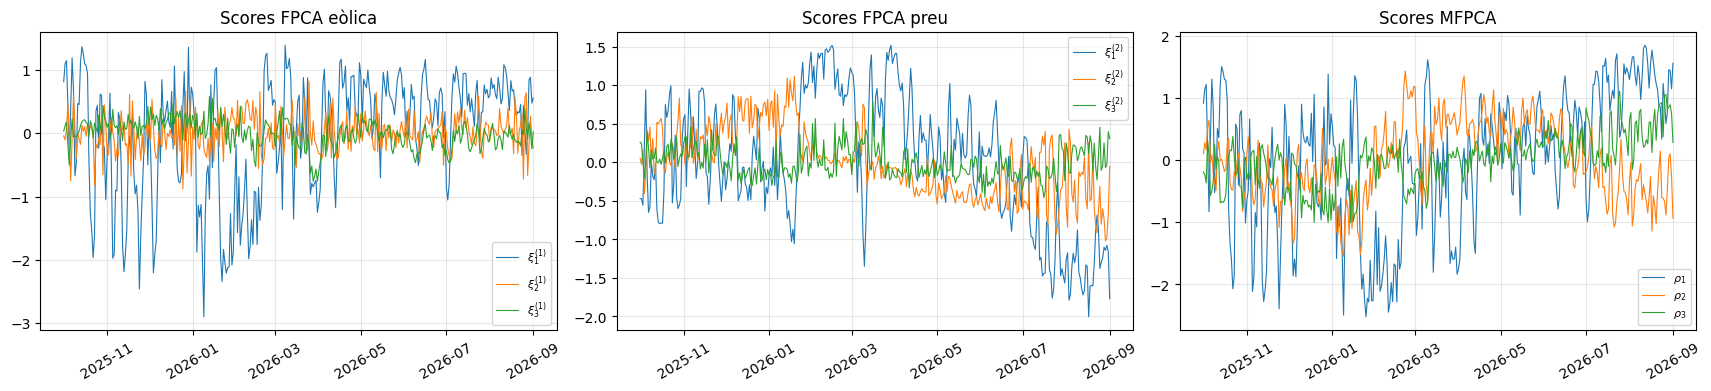

In [14]:
S_fpca = np.hstack([f_e["S"], f_p["S"]])
S_mfpca = mf["S"]
fig, axs = plt.subplots(1, 3, figsize=(17, 3.8), constrained_layout=True)
for k in range(min(3, K)):
    axs[0].plot(dies[:n_train], f_e["S"][:, k], lw=0.8, label=f"$\\xi^{{(1)}}_{k + 1}$")
    axs[1].plot(dies[:n_train], f_p["S"][:, k], lw=0.8, label=f"$\\xi^{{(2)}}_{k + 1}$")
    axs[2].plot(dies[:n_train], S_mfpca[:, k], lw=0.8, label=f"$\\rho_{k + 1}$")
for ax, t in zip(axs, ["FPCA eòlica", "FPCA preu", "MFPCA"]):
    ax.set_title(f"Scores {t}"); ax.legend(fontsize=8); ax.tick_params(axis="x", rotation=30)
plt.show()

### Observacions vs interpolació vs aproximació FPCA / MFPCA

Per a dos dies d'entrenament es comparen:

- les **observacions** discretes (punts),
- l'**aproximació amb FPCA** ($K$ components per variable),
- l'**aproximació amb MFPCA** ($K$ components conjuntes).

Després, per a tots els dies d'entrenament, l'**error funcional de reconstrucció** respecte a les
observacions (definit a la Part 7).

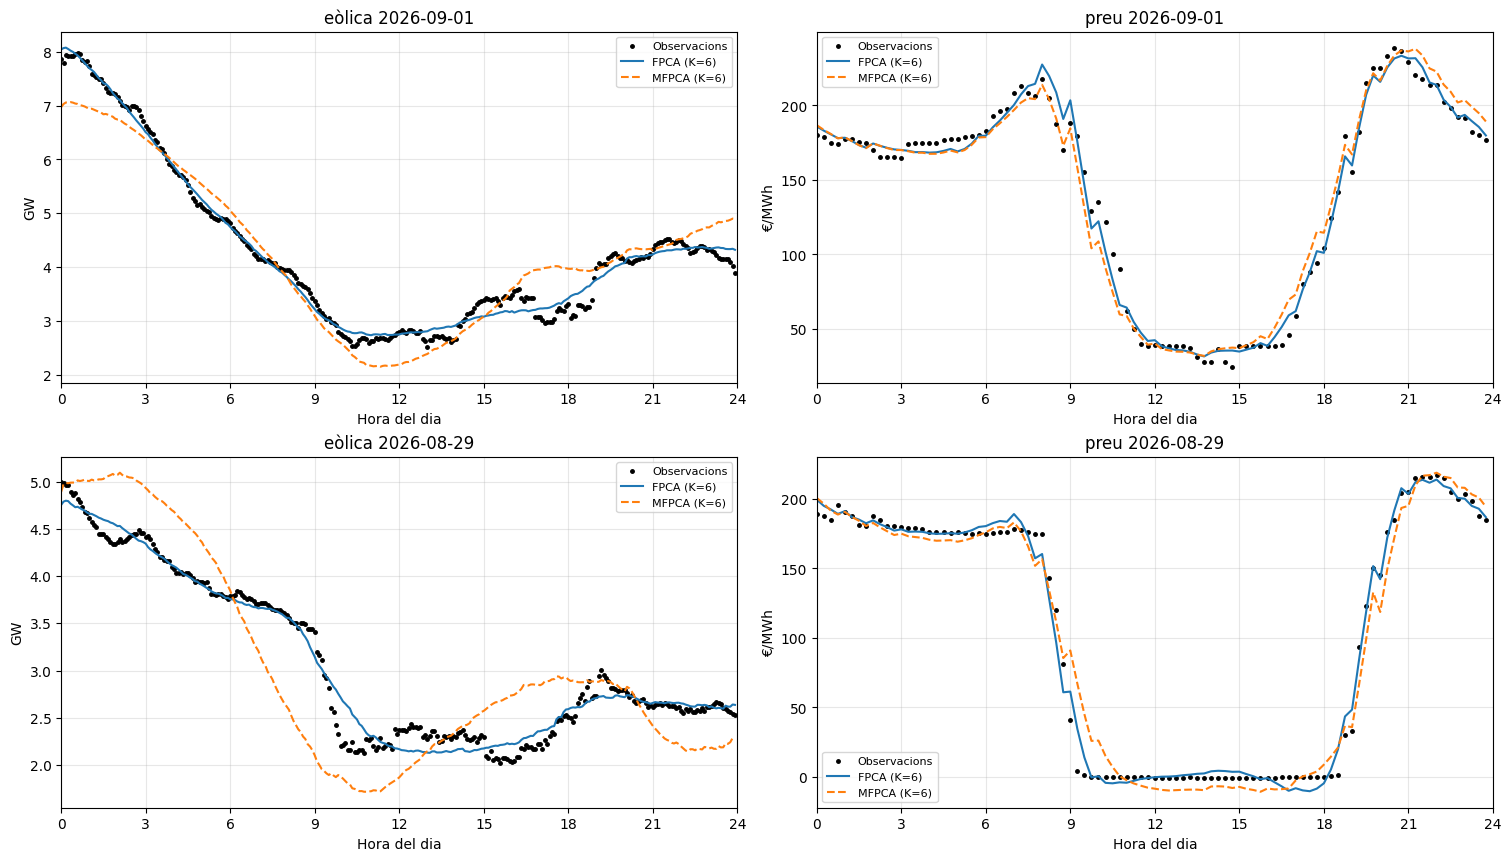

eòlica: RMSE funcional mitjà de reconstrucció  FPCA: 0.308  |  MFPCA: 0.592
preu: RMSE funcional mitjà de reconstrucció  FPCA: 6.419  |  MFPCA: 9.807


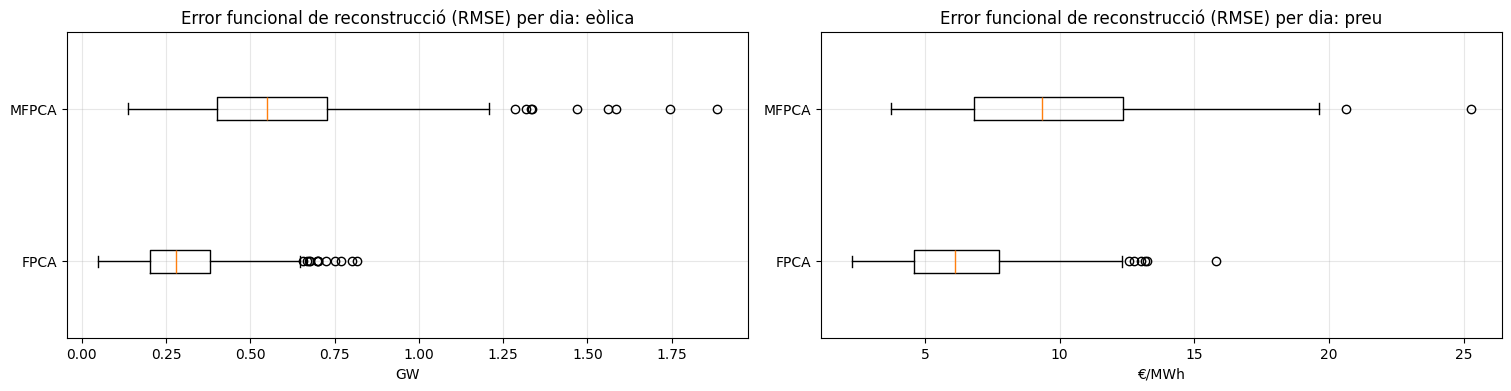

In [15]:
def reconstrueix(S_f, S_m, prep, d_idx):
    # Corbes reconstruïdes (malla fina) amb FPCA i MFPCA per als dies d_idx
    out = {}
    for j, (R, (mu, s, _)) in enumerate(zip(Rs, prep)):
        cf = mu + s * (S_f[d_idx][:, j * K:(j + 1) * K] @ [f_e, f_p][j]["Phi"].T)
        cm = mu + s * (S_m[d_idx] @ mf["Psi"][j].T)
        out[j] = (cf, cm)
    return out


def error_funcional(pred, obs, t):
    # RMSE i MAE funcionals: arrel de la mitjana integral de l'error quadràtic, i mitjana integral de |error|
    e = pred - obs
    L = t[-1] - t[0]
    return np.sqrt(trapz(e ** 2, t, axis=-1) / L), trapz(np.abs(e), t, axis=-1) / L


exemple = [n_train - 1, int(np.argmax(Xp[:n_train].std(1)))]   # últim dia i el dia més variable del preu
rec = reconstrueix(S_fpca, S_mfpca, prep, np.array(exemple))
fig, axs = plt.subplots(2, 2, figsize=(15, 8.5), constrained_layout=True)
for fila, i in enumerate(exemple):
    for col, (nom, v) in enumerate(VARS.items()):
        ax, R = axs[fila, col], v["R"]
        ax.plot(v["t"], v["X"][i], "o", ms=2.5, color="black", label="Observacions")
        if SUAVITZAT:
            ax.plot(R["tf"], R["C"][i] @ R["Bf"].T, color="tab:red", lw=1.5, label="Suavitzat")
        ax.plot(R["tf"], rec[col][0][fila] @ R["Bf"].T, color="tab:blue", lw=1.5, label=f"FPCA (K={K})")
        ax.plot(R["tf"], rec[col][1][fila] @ R["Bf"].T, color="tab:orange", lw=1.5, ls="--", label=f"MFPCA (K={K})")
        ax.set_title(f"{nom} {dies[i].date()}"); ax.set_ylabel(v["unitat"])
        ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 3)); ax.set_xlabel("Hora del dia"); ax.legend(fontsize=8)
plt.show()

tots = np.arange(n_train)
rec = reconstrueix(S_fpca, S_mfpca, prep, tots)
fig, axs = plt.subplots(1, 2, figsize=(15, 3.8), constrained_layout=True)
for col, (nom, v) in enumerate(VARS.items()):
    R = v["R"]
    caixes = {"FPCA": error_funcional(rec[col][0] @ R["B"].T, v["X"][tots], v["t"])[0],
              "MFPCA": error_funcional(rec[col][1] @ R["B"].T, v["X"][tots], v["t"])[0]}
    if SUAVITZAT:
        caixes["Només suavitzat"] = error_funcional(R["C"][tots] @ R["B"].T, v["X"][tots], v["t"])[0]
    axs[col].boxplot(list(caixes.values()), vert=False)
    axs[col].set_yticks(range(1, len(caixes) + 1), list(caixes.keys()))
    axs[col].set_title(f"Error funcional de reconstrucció (RMSE) per dia: {nom}")
    axs[col].set_xlabel(v["unitat"])
    print(f"{nom}: RMSE funcional mitjà de reconstrucció  " +
          "  |  ".join(f"{k}: {np.mean(x):.3f}" for k, x in caixes.items()))
plt.show()

La MFPCA fa servir la meitat de scores que la FPCA ($K$ contra $2K$), de manera que és normal que
reconstrueixi una mica pitjor. La pregunta important és si aquests scores es **prediuen** millor.

---
# Part 6 — Model de predicció: Random Forest sobre els scores

### Per què Random Forest

Volem predir el vector de scores de demà a partir dels scores dels dies anteriors i del dia de la setmana.
Hem triat un **Random Forest de regressió** perquè:

- **És multisortida de manera nativa**: un sol bosc prediu tots els scores alhora, i cada divisió
  dels arbres té en compte l'error de tots els scores conjuntament.
- **Captura no linealitats i interaccions** sense especificar-les (p. ex., que l'efecte del vent
  sobre el preu sigui diferent els caps de setmana), cosa que el VAR, lineal, no pot fer.
- **No suposa linealitat, estacionarietat ni residus normals.**
- **És robust amb poques dades** (~330 dies) i té pocs hiperparàmetres; promitjar centenars d'arbres
  redueix molt la variància d'un únic arbre de decisió. El *gradient boosting* podria ser més precís,
  però és més fàcil de sobreajustar amb tan poques observacions i requereix ajustar més paràmetres.

**Limitació important: un Random Forest no pot extrapolar.** Només pot predir valors dins del rang que ha
vist a l'entrenament. Si el nivell d'un score deriva (no estacionari), prediria malament. Per això el
model **prediu l'increment** dels scores i el suma al valor d'avui:

$$
\hat{\mathbf s}_{d} = \mathbf s_{d-1} + \widehat{\Delta\mathbf s}_{d},
\qquad
\widehat{\Delta\mathbf s}_{d} = \text{RF}\big(\mathbf s_{d-1},\, \mathbf s_{d-2},\, \mathbf s_{d-7},\, \text{dia de la setmana}_d\big)
$$

Si el bosc no troba cap patró, prediu un increment proper a zero i la predicció s'acosta al predictor
ingenu "repetir ahir". El test ADF de sota justifica aquesta elecció.

Hiperparàmetres (fixats a priori, sense ajustar-los amb el període de prova): 300 arbres,
`min_samples_leaf=3`, `max_features=1/3`.

**Referència:** es manté el VAR del notebook anterior (ordre per BIC, dummies del dia de la setmana)
per veure si el Random Forest aporta alguna cosa.

In [16]:
files = []
for nom, S in [("FPCA", S_fpca), ("MFPCA", S_mfpca)]:
    for k in range(S.shape[1]):
        files.append({"opció": nom, "score": k + 1,
                      "p-valor ADF (nivell)": round(adfuller(S[:, k])[1], 4),
                      "p-valor ADF (increment)": round(adfuller(np.diff(S[:, k]))[1], 4)})
pd.DataFrame(files).set_index(["opció", "score"])

p-valor ADF (nivell)  p-valor ADF (increment)
opció score                                               
FPCA  1                    0.0000                      0.0
      2                    0.0000                      0.0
      3                    0.1176                      0.0
      4                    0.0005                      0.0
      5                    0.0003                      0.0
      6                    0.0000                      0.0
      7                    0.5786                      0.0
      8                    0.8195                      0.0
      9                    0.0060                      0.0
      10                   0.0020                      0.0
      11                   0.0068                      0.0
      12                   0.0911                      0.0
MFPCA 1                    0.0913                      0.0
      2                    0.4793                      0.0
      3                    0.8349                      0.0
      4                    0.0000                      0.0
      5                    0.0000                      0.0
      6                    0.1525                      0.0

Amb $\alpha = 0.05$: si el p-valor és més gran que 0.05, no es pot rebutjar que el score sigui no
estacionari. Els increments sí que són estacionaris en tots els casos, que és el que modelitza el Random Forest.

In [17]:
dow = dies.dayofweek.to_numpy()
dummies = pd.get_dummies(dies.dayofweek).iloc[:, 1:].to_numpy(dtype=float)   # per al VAR


def variables_rf(S, d):
    # Variables explicatives per predir el dia d (fa servir les files < d)
    return np.hstack([S[d - l] for l in LAGS] + [[dow[d]]])


def noms_variables(n_scores, prefix):
    return [f"{prefix}{k + 1} (d-{l})" for l in LAGS for k in range(n_scores)] + ["dia setmana"]


def ajusta_rf(S):
    # S: scores dels dies 0..d-1. Ajusta el RF sobre els increments
    idx = range(max(LAGS), len(S))
    X_rf = np.array([variables_rf(S, i) for i in idx])
    Y_rf = np.array([S[i] - S[i - 1] for i in idx])
    return RandomForestRegressor(**RF_PARAMS).fit(X_rf, Y_rf)


def prediu_rf(S):
    d = len(S)
    rf = ajusta_rf(S)
    x_nou = variables_rf(np.vstack([S, S[-1]]), d)       # la fila d no es fa servir (només retards)
    return S[-1] + rf.predict(x_nou[None, :])[0], rf


def prediu_var(S):
    d = len(S)
    model = VAR(S, exog=dummies[:d])
    p = max(1, model.select_order(maxlags=7).bic)
    return model.fit(p).forecast(S[-p:], steps=1, exog_future=dummies[d][None, :])[0]


def prediu(d):
    # Prediu les corbes del dia d amb els dies 0..d-1 (totes les opcions). Retorna dict nom -> [eòlica, preu]
    prep_d = prepara(d)
    Zs_d = [Z for _, _, Z in prep_d]
    fu = [fpca(Z, W, K) for Z, W in zip(Zs_d, Ws)]
    mfd = mfpca(Zs_d, Ws, K)
    S_f = np.hstack([u["S"] for u in fu])
    out = {}
    for model, funcio in [("RF", lambda S: prediu_rf(S)[0]), ("VAR", prediu_var)]:
        s_f, s_m = funcio(S_f), funcio(mfd["S"])
        for opcio, coef in [("FPCA", [fu[j]["Phi"] @ s_f[j * K:(j + 1) * K] for j in range(2)]),
                            ("MFPCA", [mfd["Psi"][j] @ s_m for j in range(2)])]:
            out[f"{opcio} + {model}"] = [(mu + s * c) for (mu, s, _), c in zip(prep_d, coef)]
    return out   # coeficients de les corbes predites

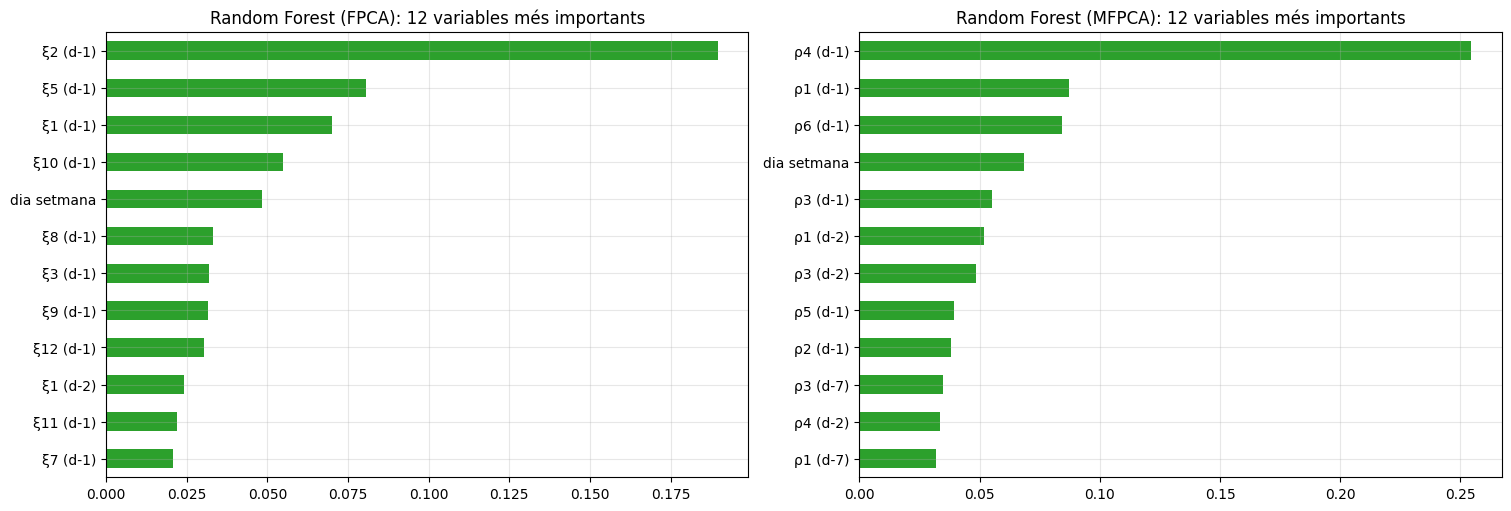

In [18]:
_, rf_f = prediu_rf(S_fpca)
_, rf_m = prediu_rf(S_mfpca)
fig, axs = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
for ax, rf, noms, t in [(axs[0], rf_f, noms_variables(2 * K, "ξ"), "FPCA"),
                        (axs[1], rf_m, noms_variables(K, "ρ"), "MFPCA")]:
    imp = pd.Series(rf.feature_importances_, index=noms).sort_values().tail(12)
    imp.plot.barh(ax=ax, color="tab:green")
    ax.set_title(f"Random Forest ({t}): 12 variables més importants")
plt.show()

Les variables més importants són els scores del dia anterior: com que el model prediu
l'increment, aprèn sobretot quant "torna" cada score cap a la seva mitjana.

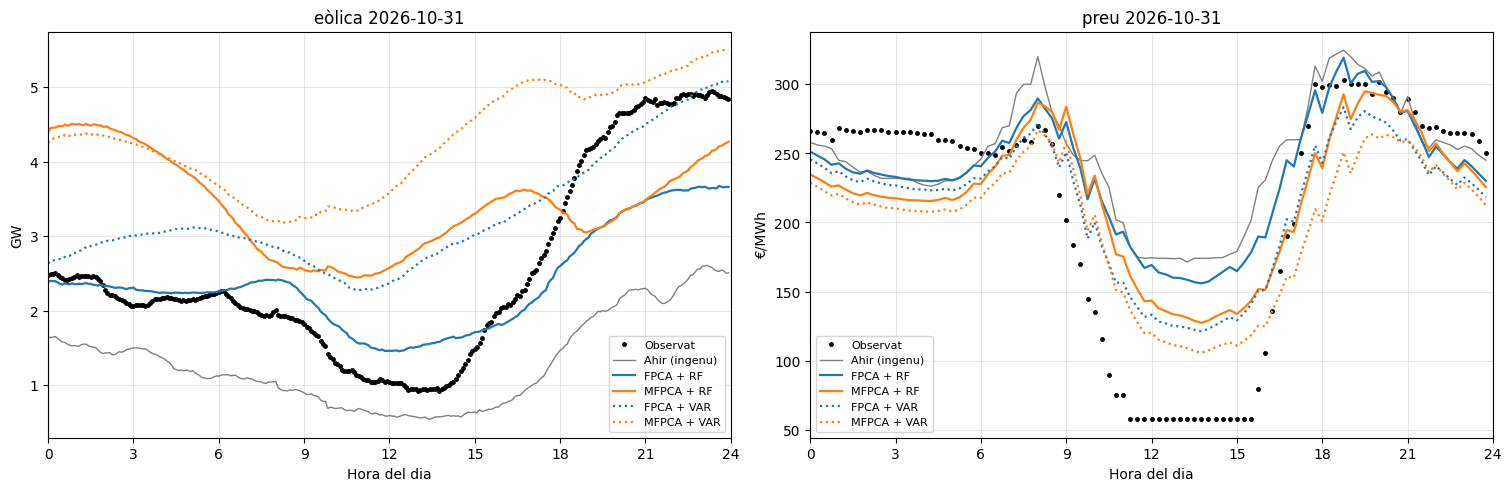

In [19]:
d = n - 1   # exemple: l'últim dia disponible
pred = prediu(d)
estils = {"FPCA + RF": ("tab:blue", "-"), "MFPCA + RF": ("tab:orange", "-"),
          "FPCA + VAR": ("tab:blue", ":"), "MFPCA + VAR": ("tab:orange", ":")}
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8), constrained_layout=True)
for j, (ax, (nom, v)) in enumerate(zip(axs, VARS.items())):
    R = v["R"]
    ax.plot(v["t"], v["X"][d], "o", ms=2.5, color="black", label="Observat")
    ax.plot(v["t"], v["X"][d - 1], color="grey", lw=1, label="Ahir (ingenu)")
    for k, (color, ls) in estils.items():
        ax.plot(R["tf"], pred[k][j] @ R["Bf"].T, color=color, ls=ls, lw=1.6, label=k)
    ax.set_title(f"{nom} {dies[d].date()}"); ax.set_ylabel(v["unitat"])
    ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 3)); ax.set_xlabel("Hora del dia"); ax.legend(fontsize=8)
plt.show()

---
# Part 7 — Avaluació rodant amb errors funcionals

Per a cadascun dels últims 60 dies $d$ es refà tota la pipeline amb els dies anteriors
(mitjana, escalat, FPCA/MFPCA i model) i es prediu el dia $d$. Referències:
"Ingenu (ahir)" (corba del dia $d-1$) i "Ingenu setmanal" (corba del dia $d-7$).

**Error funcional.** L'error del dia $d$ és la funció $e_d(t) = \hat x_d(t) - x_d(t)$ i es mesura amb
normes integrals sobre el dia, normalitzades per la longitud del domini $|\mathcal T|$ perquè tinguin les unitats de la variable:

$$
\text{RMSE}^{f}_d = \sqrt{\frac{1}{|\mathcal T|}\int_{\mathcal T} e_d(t)^2\,dt} = \frac{\|e_d\|_{L^2}}{\sqrt{|\mathcal T|}},
\qquad
\text{MAE}^{f}_d = \frac{1}{|\mathcal T|}\int_{\mathcal T} |e_d(t)|\,dt
$$

La referència $x_d(t)$ és sempre la **dada observada** (la funció lineal a trossos que passa pels punts),
Les integrals es calculen amb la regla del trapezi a la malla de les observacions.

Nota: amb una malla uniforme, el trapezi només difereix de la mitjana aritmètica dels punts en els dos
extrems (pes $\Delta/2$), així que els valors són molt semblants als de l'error puntual del notebook anterior.
La diferència és conceptual: aquí l'error és una **norma de la funció error**, independent de la malla.

In [20]:
files, prediccions = [], {}
for d in range(n_train, n):
    pred = prediu(d)
    corbes = {k: [c[j] @ Rs[j]["B"].T for j in range(2)] for k, c in pred.items()}
    corbes["Ingenu (ahir)"] = [Xe[d - 1], Xp[d - 1]]
    corbes["Ingenu setmanal"] = [Xe[d - 7], Xp[d - 7]]
    prediccions[d] = corbes
    for metode, pr in corbes.items():
        for j, (nom, v) in enumerate(VARS.items()):
            rmse, mae = error_funcional(pr[j], v["X"][d], v["t"])
            files.append({"dia": dies[d], "mètode": metode, "variable": f"{nom} ({v['unitat']})",
                          "RMSE funcional": float(rmse), "MAE funcional": float(mae)})

res = pd.DataFrame(files)
res.to_csv(f"resultats_versio_{VERSIO}.csv", index=False)
taula = res.groupby(["variable", "mètode"])[["RMSE funcional", "MAE funcional"]].mean()
ref = taula.xs("Ingenu (ahir)", level="mètode")["RMSE funcional"]
taula["millora RMSE vs ahir"] = [f"{100 * (1 - v / ref[var_]):.1f} %"
                                 for (var_, _), v in taula["RMSE funcional"].items()]
taula.round(2)

RMSE funcional  MAE funcional  \
variable     mètode                                           
eòlica (GW)  FPCA + RF                  2.27           1.94   
             FPCA + VAR                 2.01           1.65   
             Ingenu (ahir)              3.00           2.58   
             Ingenu setmanal            3.77           3.34   
             MFPCA + RF                 2.43           2.07   
             MFPCA + VAR                2.13           1.81   
preu (€/MWh) FPCA + RF                 37.98          30.25   
             FPCA + VAR                33.00          26.28   
             Ingenu (ahir)             43.28          34.29   
             Ingenu setmanal           55.48          44.02   
             MFPCA + RF                37.88          29.92   
             MFPCA + VAR               35.39          27.89   

                             millora RMSE vs ahir  
variable     mètode                                
eòlica (GW)  FPCA + RF                     24.4 %  
             FPCA + VAR                    33.0 %  
             Ingenu (ahir)                  0.0 %  
             Ingenu setmanal              -25.6 %  
             MFPCA + RF                    19.1 %  
             MFPCA + VAR                   28.9 %  
preu (€/MWh) FPCA + RF                     12.2 %  
             FPCA + VAR                    23.8 %  
             Ingenu (ahir)                  0.0 %  
             Ingenu setmanal              -28.2 %  
             MFPCA + RF                    12.5 %  
             MFPCA + VAR                   18.2 %

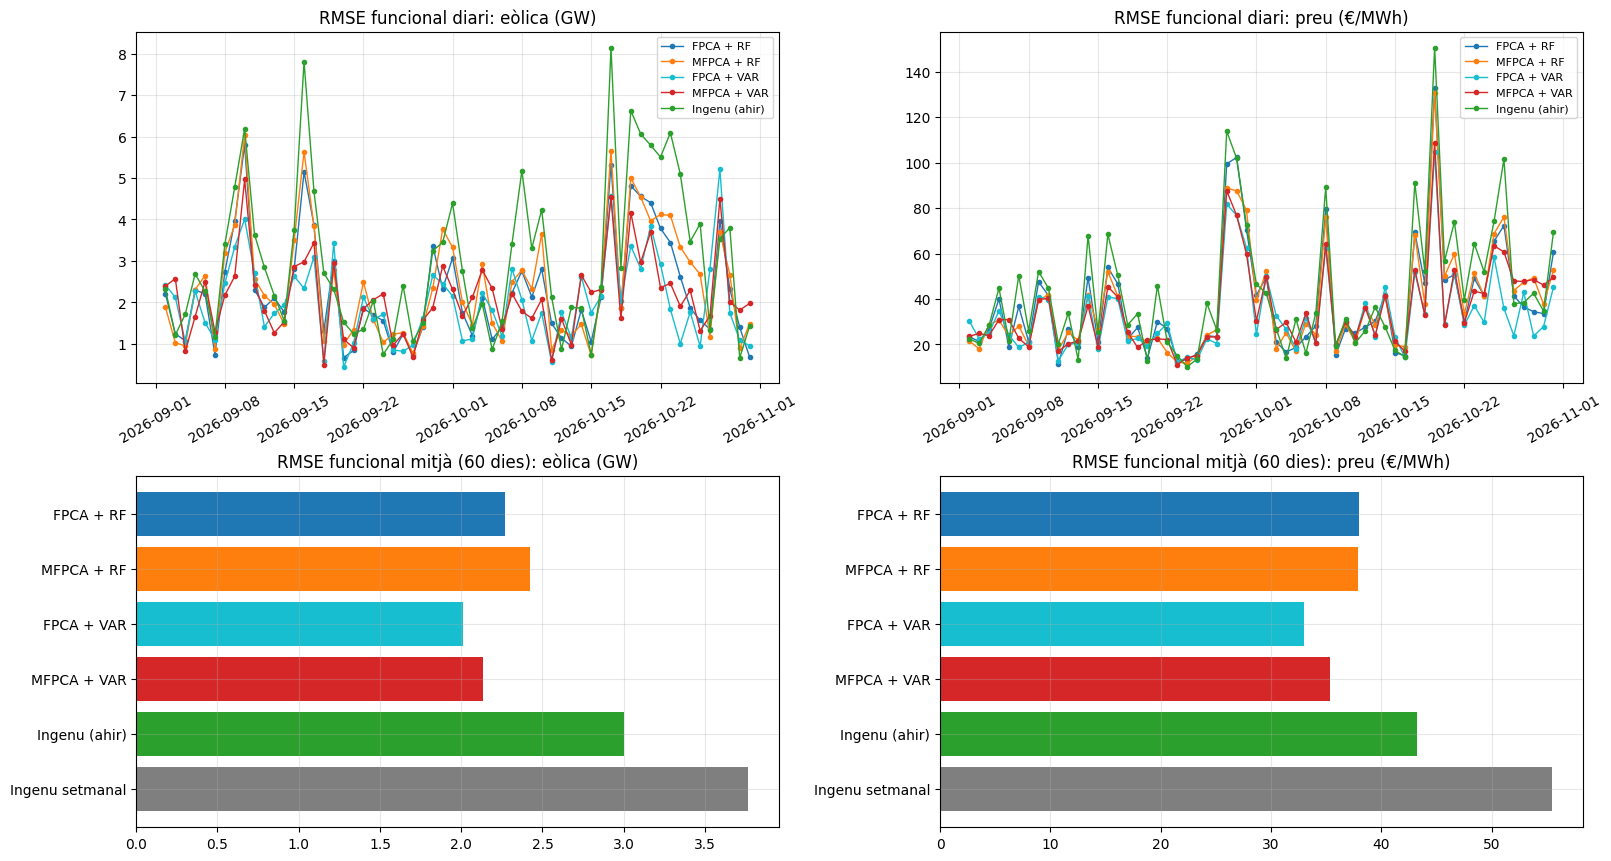

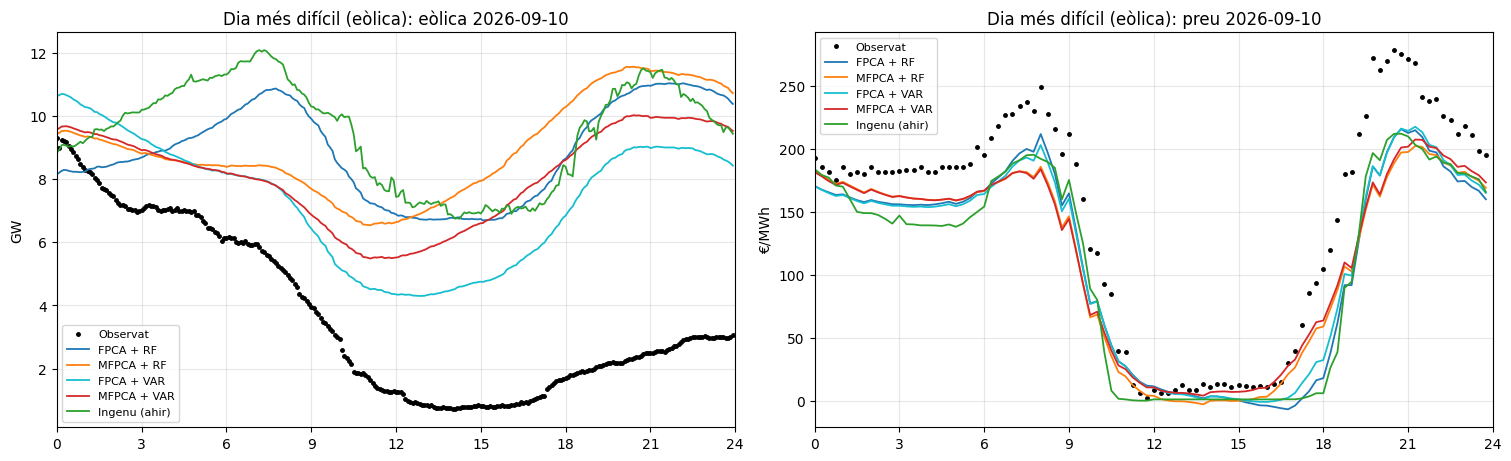

In [21]:
metodes = ["FPCA + RF", "MFPCA + RF", "FPCA + VAR", "MFPCA + VAR", "Ingenu (ahir)"]
colors = ["tab:blue", "tab:orange", "tab:cyan", "tab:red", "tab:green"]
fig, axs = plt.subplots(2, 2, figsize=(16, 8.5), constrained_layout=True)
for col, var_ in enumerate(res["variable"].unique()):
    sub = res[res["variable"] == var_]
    for metode, color in zip(metodes, colors):
        s = sub[sub["mètode"] == metode]
        axs[0, col].plot(s["dia"], s["RMSE funcional"], marker="o", ms=3, lw=1, color=color, label=metode)
    axs[0, col].set_title(f"RMSE funcional diari: {var_}"); axs[0, col].legend(fontsize=8)
    axs[0, col].tick_params(axis="x", rotation=30)
    mitjanes = sub.groupby("mètode")["RMSE funcional"].mean().reindex(metodes + ["Ingenu setmanal"])
    axs[1, col].barh(mitjanes.index, mitjanes.values, color=colors + ["tab:gray"])
    axs[1, col].invert_yaxis()
    axs[1, col].set_title(f"RMSE funcional mitjà (60 dies): {var_}")
plt.show()

# Dia amb l'error més gran de l'eòlica (per al millor model) i com el prediuen els models
sub = res[(res["mètode"] == "FPCA + RF") & res["variable"].str.startswith("eòlica")]
d = dies.get_loc(sub.loc[sub["RMSE funcional"].idxmax(), "dia"])
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5), constrained_layout=True)
for j, (ax, (nom, v)) in enumerate(zip(axs, VARS.items())):
    ax.plot(v["t"], v["X"][d], "o", ms=2.5, color="black", label="Observat")
    for metode, color in zip(metodes, colors):
        ax.plot(v["t"], prediccions[d][metode][j], color=color, lw=1.3, label=metode)
    ax.set_title(f"Dia més difícil (eòlica): {nom} {dies[d].date()}"); ax.set_ylabel(v["unitat"])
    ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 3)); ax.legend(fontsize=8)
plt.show()

---
# Conclusió

*(Resultats amb dades de l'1-10-2025 al 31-10-2026; prova del 2-9-2026 al 31-10-2026.)*

- **Representació (Part 2).** Sense suavitzat, cada dia és el vector de valors observats i les integrals es fan
  amb el trapezi ($W$ diagonal). La nostra FPCA dona exactament els mateixos valors propis que `UFPCA` de FDApy.
- **Variància (Parts 3 i 5).** Totes les variàncies són mostrals ($n-1$) i **funcionals**: es calculen com
  $\operatorname{tr}(\widehat V W) = \sum_l w_l\, s^2(t_l)$. Ho confirma que la suma de tots els valors propis
  de la FPCA val exactament 1 (la variància total funcional després d'escalar), mentre que la total discreta
  val 12.0 a l'eòlica i 4.1 al preu (≈ 1/Δ vegades més).
- **Nombre de components.** Per al 95 %: $K_1 = 3$ (eòlica), $K_2 = 4$ (preu), $M = 6$ (MFPCA), de manera que
  s'usa $K = 6$ per a tot. La FPCA reconstrueix millor (fa servir 12 scores contra 6).
- **Predicció (Part 7, 60 dies, error funcional).** El Random Forest millora clarament les referències
  ingènues (eòlica: −24 % FPCA i −19 % MFPCA d'RMSE respecte a "ahir"; preu: −12 % i −12 %), però
  **el VAR és millor en tots els casos** (eòlica −33 % i −29 %; preu −24 % i −18 %). Amb ~330 dies
  d'entrenament, la dinàmica dels scores és sobretot lineal (persistència i retorn a la mitjana), i
  això ho captura millor un VAR que un model per arbres.
- **FPCA vs MFPCA.** Amb el mateix $K$, la FPCA prediu millor que la MFPCA, excepte al preu amb Random
  Forest, on són pràcticament iguals (38.0 vs 37.9 €/MWh).
- **Sense suavitzat vs suavitzat.** Els errors són pràcticament iguals que a la versió A, així que el
  suavitzat inicial no aporta millora a la predicció.
- **Limitacions.** El Random Forest no pot extrapolar (per això prediu increments), els hiperparàmetres no
  s'han ajustat, i 60 dies de prova són pocs per afirmar diferències petites (caldria un test de
  Diebold-Mariano). Afegir la previsió eòlica de REE (indicador 541) com a variable explicativa del
  Random Forest és la millora amb més potencial.